(46, 41)
1.0


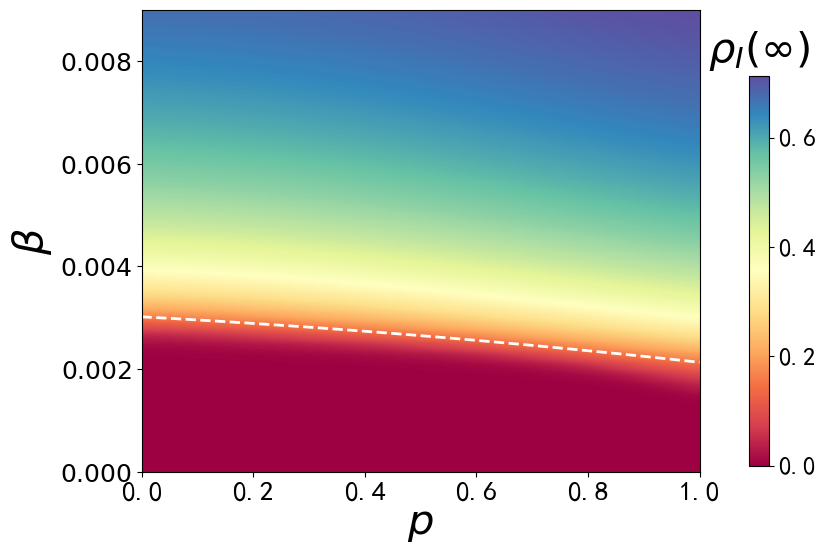

In [2]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib
import matplotlib.ticker as ticker  # 导入 ticker 用于自定义刻度格式

matplotlib.rcParams['font.sans-serif'] = ['SimHei']  # 设置字体为 SimHei (黑体)
matplotlib.rcParams['axes.unicode_minus'] = False  # 解决坐标轴负号显示问题

p_move_values = np.arange(0.0, 1.025, 0.025)
beta_values = np.arange(0.0, 0.0092, 0.0002)

results_matrix = pd.read_csv('./test1_data/simulation_results_0927.csv', index_col=0)

# 保存对应的beta和p
beta_p_above_threshold = []

for i, p in enumerate(p_move_values):
    for j, beta in enumerate(beta_values):
        if results_matrix.iloc[j, i] > 0.13:
            beta_p_above_threshold.append((beta, p))
            break 

# 将找到的 beta 和 p 提取为单独的列表
beta_above_threshold = [item[0] for item in beta_p_above_threshold]
p_above_threshold = [item[1] for item in beta_p_above_threshold]

# 多项式拟合，degree=2 表示二次多项式
coefficients = np.polyfit(p_above_threshold, beta_above_threshold, 2)

# 生成 p_fit 点，用于绘制平滑的曲线
p_fit = np.linspace(min(p_above_threshold), max(p_above_threshold), 100)

# 计算 p_fit 对应的 beta_fit（二次多项式的值）
beta_fit = np.polyval(coefficients, p_fit)

# 绘制热力图
plt.figure(figsize=(9, 6))
plt.imshow(results_matrix, cmap='Spectral', aspect='auto', origin='lower', interpolation='gaussian',
           extent=[p_move_values[0], p_move_values[-1], beta_values[0], beta_values[-1]])

print(results_matrix.shape)
print(results_matrix.columns[-1])

# 创建 colorbar 并设置标签及刻度字体大小
colorbar = plt.colorbar(label='')
# colorbar.set_label('Colorbar Label', fontsize=16)  # 设置 colorbar 标签字体大小
colorbar.ax.tick_params(labelsize='18')  # 设置 colorbar 刻度标签字体大小
# 移动 colorbar 标签到最上方
colorbar.ax.set_title(r'$\rho_I \left ( \infty \right ) $', fontsize=30, pad=10)  # 设置标签字体大小并调整与colorbar的距离

# 设置 colorbar 的大小（高度）为原图的一半
colorbar.ax.set_position([0.8, 0.12, 0.3, 0.65])  # [left, bottom, width, height]

# 设置x轴和y轴标签
plt.xlabel(r'$p$',fontsize='30')
plt.ylabel(r'$\beta$',fontsize='30')

# 自定义y轴刻度为科学计数法
# ax = plt.gca()  # 获取当前坐标轴
# formatter = ticker.ScalarFormatter(useMathText=True)
# formatter.set_powerlimits((-3, 2))  # 设置当数值在 1e-2 到 1e2 之外时自动使用科学计数法
# ax.yaxis.set_major_formatter(formatter)
plt.yticks([0, 0.002, 0.004,0.006,0.008 ], [r'$0.000$', r'$0.002$', r'$0.004$',r'$0.006$',r'$0.008$'], fontsize='18')
plt.xticks(fontsize='20')

# # 在原热力图上绘制拟合的二次曲线
plt.plot(p_fit, beta_fit, 'w--', linewidth='2')
# 保存图像
plt.savefig('WS_heatmap.pdf', dpi=300, bbox_inches='tight')
plt.show()


In [4]:
beta_values = np.arange(0.0, 0.0092, 0.0002)
print(len(beta_values))
print(beta_values)

p_move_values = np.arange(0.0, 1.025, 0.025)
print(len(p_move_values))
p_move_values


46
[0.     0.0002 0.0004 0.0006 0.0008 0.001  0.0012 0.0014 0.0016 0.0018
 0.002  0.0022 0.0024 0.0026 0.0028 0.003  0.0032 0.0034 0.0036 0.0038
 0.004  0.0042 0.0044 0.0046 0.0048 0.005  0.0052 0.0054 0.0056 0.0058
 0.006  0.0062 0.0064 0.0066 0.0068 0.007  0.0072 0.0074 0.0076 0.0078
 0.008  0.0082 0.0084 0.0086 0.0088 0.009 ]
41


array([0.   , 0.025, 0.05 , 0.075, 0.1  , 0.125, 0.15 , 0.175, 0.2  ,
       0.225, 0.25 , 0.275, 0.3  , 0.325, 0.35 , 0.375, 0.4  , 0.425,
       0.45 , 0.475, 0.5  , 0.525, 0.55 , 0.575, 0.6  , 0.625, 0.65 ,
       0.675, 0.7  , 0.725, 0.75 , 0.775, 0.8  , 0.825, 0.85 , 0.875,
       0.9  , 0.925, 0.95 , 0.975, 1.   ])